# Taller 2 — Notebook 05: Evaluación cuantitativa de los modelos

**MINE-4101 · Predicción de churn para FinAlpes** · **Integrantes:** Daniel Triviño · Nicolás Bedoya

Entregable 3. Evalúa una sola vez, en el conjunto de prueba, los tres modelos que se ajustaron y guardaron en el `04`.
El conjunto de prueba no se usó para elegir nada: el modelo se eligió por PR-AUC en validación cruzada y el umbral de
decisión se fija aquí con predicciones de validación cruzada sobre entrenamiento.

- Métricas en prueba con dos umbrales, frente a la línea base "nunca abandona".
- Matriz de confusión, curvas precisión-recall y ROC, y brecha entre entrenamiento, validación y prueba.
- Intervalos de confianza por bootstrapping y comparación pareada entre modelos (bootstrapping y McNemar), con un
  umbral de diferencia relevante fijado antes de ver los resultados.
- Calibración de las probabilidades, desempeño por segmento y oportunidades de mejora.

> Ejecutar después de `04_modelado`.

In [1]:
import json
import os

import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from statsmodels.stats.contingency_tables import mcnemar
from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

RUTA_PROCESADOS = '../data/processed'
RUTA_MODELOS = f'{RUTA_PROCESADOS}/modelos'
RUTA_FIGS = '../figs'
os.makedirs(RUTA_FIGS, exist_ok=True)

SEMILLA = 42             # la misma del 04
B = 1000                 # réplicas de bootstrapping
UMBRAL_RELEVANTE = 0.02  # diferencia mínima entre modelos que consideramos relevante (fijada antes de ver resultados)

## 1. Datos, partición y modelos

Se usa la misma partición del `04` (`churn_particion.parquet`) y los modelos ya ajustados con todo el entrenamiento.
La SVM se guardó calibrada para que entregue probabilidades.

In [2]:
df = pd.read_parquet(f'{RUTA_PROCESADOS}/churn_particion.parquet')
with open(f'{RUTA_MODELOS}/seleccion.json', encoding='utf-8') as f:
    seleccion = json.load(f)

OBJETIVO = 'churn'
VARIABLES_MODELO = seleccion['variables_modelo']
ELEGIDO = seleccion['modelo_elegido']

X = df[VARIABLES_MODELO].astype(float)
y = df[OBJETIVO]
es_prueba = (df['particion'] == 'prueba').to_numpy()
X_train, y_train = X[~es_prueba], y[~es_prueba]
X_test, y_test = X[es_prueba], y[es_prueba]

modelos = {nombre: joblib.load(f'{RUTA_MODELOS}/{archivo}') for nombre, archivo in seleccion['archivos'].items()}
NOMBRES = list(modelos)
TASA_PRUEBA = y_test.mean()

print(f'Entrenamiento: {len(y_train):,} clientes (churn {y_train.mean() * 100:.1f}%)  |  '
      f'prueba: {len(y_test):,} clientes (churn {TASA_PRUEBA * 100:.1f}%, {y_test.sum()} abandonos)')
print(f'Modelo elegido en el 04: {ELEGIDO}  |  hiperparámetros: {seleccion["hiperparametros"][ELEGIDO]}')

Entrenamiento: 7,988 clientes (churn 20.4%)  |  prueba: 1,997 clientes (churn 20.4%, 407 abandonos)
Modelo elegido en el 04: XGBoost  |  hiperparámetros: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}


## 2. Umbral de decisión

Los modelos entregan una probabilidad de abandono; para decidir a quién contactar hace falta un umbral. Con el desbalance
(\~20 % de abandonos), el umbral por defecto de 0,5 marca a muy pocos clientes. Para cada modelo se elige el umbral que
maximiza el F1 sobre las **predicciones de validación cruzada en entrenamiento** (las mismas 5 particiones del `04`), sin
mirar la prueba. El umbral que maximiza la ganancia se calcula en el `07` con los costos de la campaña.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def umbral_max_f1(y_real, prob):
    """Umbral que maximiza el F1 sobre un conjunto de probabilidades."""
    precision, recall, umbrales = precision_recall_curve(y_real, prob)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return umbrales[np.argmax(f1[:-1])]

# Predicciones de validación cruzada en entrenamiento (cada cliente predicho por un modelo que no lo vio)
prob_cv = {n: cross_val_predict(clone(m), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
           for n, m in modelos.items()}
prob_train = {n: m.predict_proba(X_train)[:, 1] for n, m in modelos.items()}   # ajuste (datos ya vistos)
prob_test = {n: m.predict_proba(X_test)[:, 1] for n, m in modelos.items()}     # prueba (una sola vez)

UMBRALES = {n: umbral_max_f1(y_train, p) for n, p in prob_cv.items()}
display(pd.Series(UMBRALES, name='umbral_max_F1_en_CV').to_frame())

,umbral_max_F1_en_CV
Regresión logística,0.326
SVM,0.209
XGBoost,0.329


## 3. Métricas en el conjunto de prueba

- **PR-AUC** (precisión promedio): qué tan bien ordena el modelo a los clientes por riesgo, mirando solo la clase que
  abandona. Su línea base es la tasa de abandono, no 0,5.
- **ROC-AUC**: probabilidad de que un cliente que abandona reciba más riesgo que uno que se queda.
- **Precisión**: de los clientes contactados, cuántos sí iban a abandonar (cuánto del presupuesto de la campaña llega a
  quien lo necesita). **Recall**: de los clientes que abandonan, a cuántos alcanza la campaña. **F1**: equilibrio
  entre las dos.
- **Brier**: error cuadrático de la probabilidad; importa porque el `07` usa las probabilidades para calcular el valor.

In [4]:
def metricas(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {'pr_auc': average_precision_score(y_real, prob), 'roc_auc': roc_auc_score(y_real, prob),
            'brier': brier_score_loss(y_real, prob), 'exactitud': accuracy_score(y_real, pred),
            'precision': precision_score(y_real, pred, zero_division=0), 'recall': recall_score(y_real, pred),
            'f1': f1_score(y_real, pred), 'pct_contactados': pred.mean() * 100}

filas = []
for n in NOMBRES:
    filas.append({'modelo': n, 'umbral': f'máx. F1 en CV ({UMBRALES[n]:.2f})', **metricas(y_test, prob_test[n], UMBRALES[n])})
    filas.append({'modelo': n, 'umbral': '0,50', **metricas(y_test, prob_test[n], 0.5)})
filas.append({'modelo': 'Línea base: nunca abandona', 'umbral': '—', 'pr_auc': TASA_PRUEBA, 'roc_auc': 0.5,
              'brier': brier_score_loss(y_test, np.full(len(y_test), y_train.mean())),
              'exactitud': 1 - TASA_PRUEBA, 'precision': np.nan, 'recall': 0.0, 'f1': 0.0, 'pct_contactados': 0.0})
tabla_prueba = pd.DataFrame(filas).set_index(['modelo', 'umbral'])
display(tabla_prueba)

pr_auc  roc_auc  brier  exactitud  precision  recall    f1  pct_contactados
modelo                     umbral                                                                                           
Regresión logística        máx. F1 en CV (0.33)   0.570    0.812  0.124      0.803      0.517   0.518 0.518           20.431
                           0,50                   0.570    0.812  0.124      0.830      0.687   0.302 0.420            8.963
SVM                        máx. F1 en CV (0.21)   0.617    0.785  0.118      0.831      0.595   0.531 0.561           18.177
                           0,50                   0.617    0.785  0.118      0.848      0.786   0.351 0.486            9.114
XGBoost                    máx. F1 en CV (0.33)   0.662    0.840  0.111      0.838      0.615   0.545 0.578           18.077
                           0,50                   0.662    0.840  0.111      0.850      0.769   0.376 0.505            9.965
Línea base: nunca abandona —                      0.204    0.500  0.162      0.796        NaN   0.000 0.000            0.000

In [5]:
el = tabla_prueba.loc[(ELEGIDO, f'máx. F1 en CV ({UMBRALES[ELEGIDO]:.2f})')]
base = tabla_prueba.loc[('Línea base: nunca abandona', '—')]
print(f'{ELEGIDO} en prueba (umbral {UMBRALES[ELEGIDO]:.2f}): PR-AUC {el.pr_auc:.3f} '
      f'({el.pr_auc / TASA_PRUEBA:.1f} veces la línea base de {TASA_PRUEBA:.3f}), ROC-AUC {el.roc_auc:.3f}')
print(f'  contacta al {el.pct_contactados:.1f}% de los clientes; precisión {el.precision:.3f} '
      f'({el.precision / TASA_PRUEBA:.1f} veces la tasa de abandono), recall {el.recall:.3f}, F1 {el.f1:.3f}')
print(f'  exactitud {el.exactitud:.3f} frente a {base.exactitud:.3f} de "nunca abandona"')

XGBoost en prueba (umbral 0.33): PR-AUC 0.662 (3.2 veces la línea base de 0.204), ROC-AUC 0.840
  contacta al 18.1% de los clientes; precisión 0.615 (3.0 veces la tasa de abandono), recall 0.545, F1 0.578
  exactitud 0.838 frente a 0.796 de "nunca abandona"


**Qué vemos:**

- XGBoost es el mejor en todas las métricas de prueba. Con su umbral (0,33) contacta al 18 % de los clientes. El 62 % de
  los contactados sí abandona (precisión 0,615), 3,0 veces la tasa de abandono del 20,4 %, y la campaña alcanza al 55 %
  de los que abandonan (recall 0,545). Su PR-AUC (0,662) es 3,2 veces la línea base (0,204).
- La exactitud engaña. "Nunca abandona" ya acierta el 79,6 % y XGBoost solo sube al 83,8 %, aunque detecta a más de la
  mitad de los que se van. Por eso no se usa para elegir.
- El umbral cambia mucho el resultado. Con 0,50 la precisión sube a 0,77, pero el recall cae a 0,38: se escapan 6 de
  cada 10 clientes que abandonan. Elegir el umbral es una decisión de negocio (cuánto cuesta contactar frente a perder
  un cliente) y se resuelve con los costos en el `07`.

### 3.1 Matriz de confusión del modelo elegido

Umbral 0.33 (máx. F1 en CV): VP=222, FP=139, FN=185, VN=1451
Umbral 0,50: VP=153, FP=46, FN=254, VN=1544


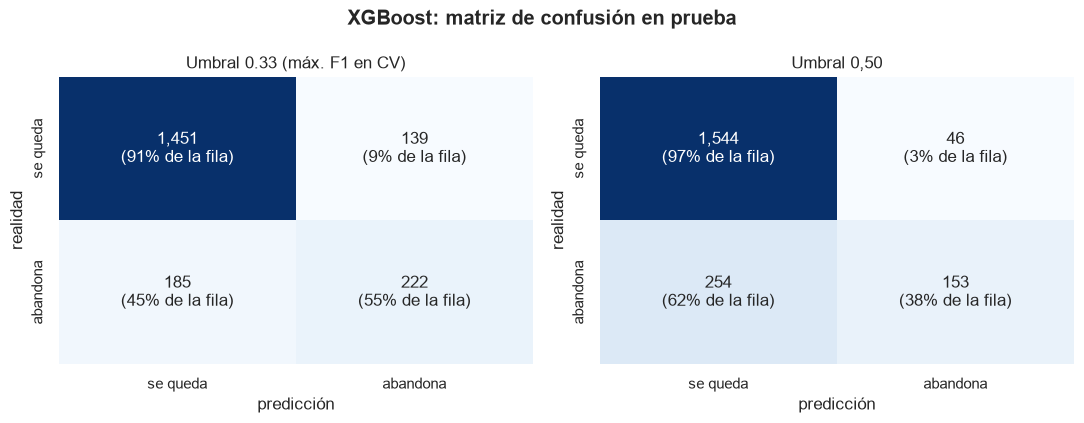

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (titulo, umbral) in zip(axes, [(f'Umbral {UMBRALES[ELEGIDO]:.2f} (máx. F1 en CV)', UMBRALES[ELEGIDO]),
                                        ('Umbral 0,50', 0.5)]):
    mc = confusion_matrix(y_test, (prob_test[ELEGIDO] >= umbral).astype(int))
    etiquetas = np.array([[f'{v:,}\n({v / mc[i].sum() * 100:.0f}% de la fila)' for v in fila] for i, fila in enumerate(mc)])
    sns.heatmap(mc, annot=etiquetas, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['se queda', 'abandona'], yticklabels=['se queda', 'abandona'])
    ax.set_xlabel('predicción'); ax.set_ylabel('realidad'); ax.set_title(titulo)
    vn, fp, fn, vp = mc.ravel()
    print(f'{titulo}: VP={vp}, FP={fp}, FN={fn}, VN={vn}')
fig.suptitle(f'{ELEGIDO}: matriz de confusión en prueba', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/05_matriz_confusion.png', bbox_inches='tight'); plt.show()

**Qué vemos:** con el umbral 0,33, de los 361 clientes marcados, 222 sí abandonan (VP) y 139 son falsas alarmas (FP):
ofertas que se pagan sin necesidad. Se escapan 185 abandonos (FN). Con 0,50 las falsas alarmas bajan a 46, pero se
escapan 254 de los 407 abandonos. Para la empresa, un FP cuesta una oferta y un FN cuesta el ingreso de un cliente
perdido. Como el segundo suele ser mayor, conviene un umbral bajo; cuánto exactamente lo dice el `07`.

### 3.2 Curvas precisión-recall y ROC en prueba

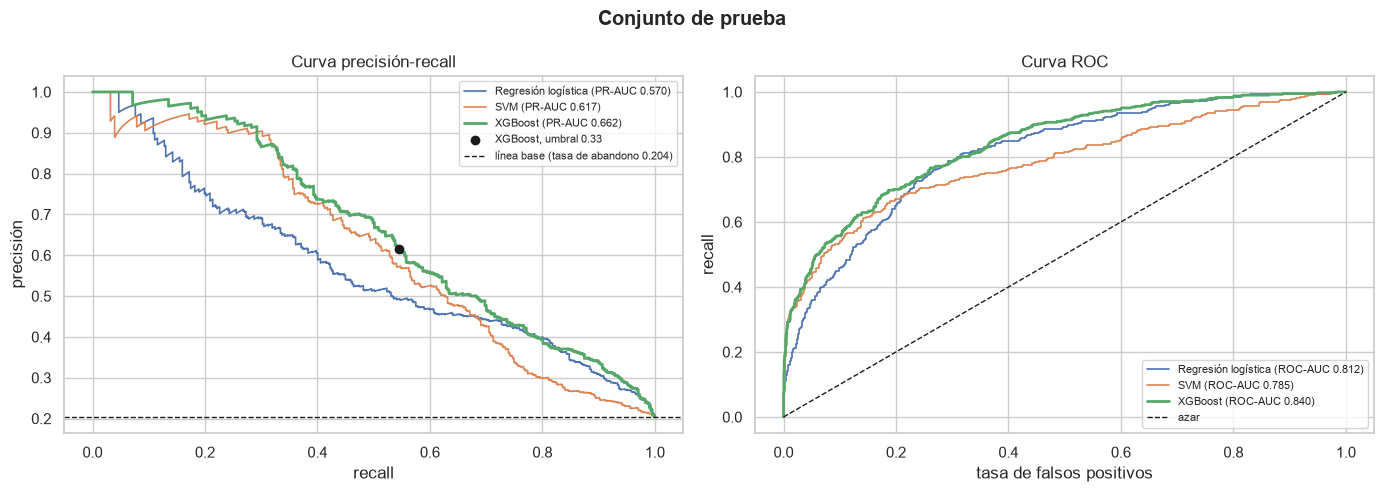

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n in NOMBRES:
    precision, recall, _ = precision_recall_curve(y_test, prob_test[n])
    axes[0].plot(recall, precision, lw=2 if n == ELEGIDO else 1.2,
                 label=f'{n} (PR-AUC {average_precision_score(y_test, prob_test[n]):.3f})')
    fpr, tpr, _ = roc_curve(y_test, prob_test[n])
    axes[1].plot(fpr, tpr, lw=2 if n == ELEGIDO else 1.2, label=f'{n} (ROC-AUC {roc_auc_score(y_test, prob_test[n]):.3f})')
pto = metricas(y_test, prob_test[ELEGIDO], UMBRALES[ELEGIDO])
axes[0].scatter(pto['recall'], pto['precision'], color='k', zorder=5, label=f'{ELEGIDO}, umbral {UMBRALES[ELEGIDO]:.2f}')
axes[0].axhline(TASA_PRUEBA, color='k', ls='--', lw=1, label=f'línea base (tasa de abandono {TASA_PRUEBA:.3f})')
axes[0].set_title('Curva precisión-recall'); axes[0].set_xlabel('recall'); axes[0].set_ylabel('precisión')
axes[1].plot([0, 1], [0, 1], color='k', ls='--', lw=1, label='azar')
axes[1].set_title('Curva ROC'); axes[1].set_xlabel('tasa de falsos positivos'); axes[1].set_ylabel('recall')
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle('Conjunto de prueba', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/05_curvas_prueba.png', bbox_inches='tight'); plt.show()

**Qué vemos:** la curva precisión-recall de XGBoost queda por encima de las otras dos en casi todo el rango: con
cualquier cobertura de la campaña logra más precisión. La ROC se ve más optimista (0,84) que la PR (0,66) porque, con
un 80 % de clientes que se quedan, muchas falsas alarmas producen una tasa de falsos positivos pequeña. Por eso la
selección se hizo con PR-AUC.

### 3.3 Entrenamiento, validación cruzada y prueba

Si el modelo memorizara el entrenamiento, sus métricas de ajuste serían mucho mejores que las de validación y prueba.
Todas con el umbral de cada modelo.

In [8]:
filas = []
for n in NOMBRES:
    for conjunto, yy, pp in [('entrenamiento (ajuste)', y_train, prob_train[n]),
                             ('validación cruzada', y_train, prob_cv[n]),
                             ('prueba', y_test, prob_test[n])]:
        m = metricas(yy, pp, UMBRALES[n])
        filas.append({'modelo': n, 'conjunto': conjunto, **{k: m[k] for k in ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1']}})
brecha = pd.DataFrame(filas).set_index(['modelo', 'conjunto'])
display(brecha)

pr_auc  roc_auc  precision  recall    f1
modelo              conjunto                                                        
Regresión logística entrenamiento (ajuste)   0.596    0.815      0.545   0.560 0.553
                    validación cruzada       0.594    0.814      0.541   0.559 0.550
                    prueba                   0.570    0.812      0.517   0.518 0.518
SVM                 entrenamiento (ajuste)   0.671    0.832      0.637   0.558 0.595
                    validación cruzada       0.645    0.815      0.610   0.557 0.582
                    prueba                   0.617    0.785      0.595   0.531 0.561
XGBoost             entrenamiento (ajuste)   0.697    0.859      0.645   0.585 0.614
                    validación cruzada       0.677    0.847      0.634   0.577 0.605
                    prueba                   0.662    0.840      0.615   0.545 0.578

**Qué vemos:** los tres modelos pierden poco entre entrenamiento, validación cruzada y prueba. En XGBoost, la PR-AUC
pasa de 0,697 a 0,677 y a 0,662. No hay sobreajuste importante: la configuración elegida es conservadora (árboles de
profundidad 3, tasa de aprendizaje 0,03, 200 árboles). La prueba sale algo por debajo de la validación cruzada en los
tres modelos; en XGBoost la diferencia (\~0,015) cabe dentro de la incertidumbre que muestra la sección 4.

## 4. Incertidumbre de las métricas (bootstrapping)

La prueba tiene \~2.000 clientes y \~400 abandonos: con otra muestra las métricas cambiarían. Se remuestrea el conjunto
de prueba con reemplazo (B = 1.000 réplicas, semilla 42) y se calcula cada métrica en cada réplica, sin reentrenar.
Todos los modelos usan **las mismas réplicas**, así que las diferencias entre ellos quedan pareadas. El intervalo del 95 %
es el de percentiles 2,5 y 97,5.

In [9]:
rng = np.random.default_rng(SEMILLA)
yt = y_test.to_numpy()
idx_boot = rng.integers(0, len(yt), size=(B, len(yt)))
METRICAS_BOOT = ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1']

def bootstrap(prob, umbral):
    pred = (prob >= umbral).astype(int)
    res = np.empty((B, len(METRICAS_BOOT)))
    for b, idx in enumerate(idx_boot):
        yy, pp, dd = yt[idx], prob[idx], pred[idx]
        res[b] = [average_precision_score(yy, pp), roc_auc_score(yy, pp), precision_score(yy, dd, zero_division=0),
                  recall_score(yy, dd), f1_score(yy, dd)]
    return pd.DataFrame(res, columns=METRICAS_BOOT)

boot = {n: bootstrap(prob_test[n], UMBRALES[n]) for n in NOMBRES}

filas = []
for n in NOMBRES:
    obs = metricas(y_test, prob_test[n], UMBRALES[n])
    for m in METRICAS_BOOT:
        inf, sup = np.percentile(boot[n][m], [2.5, 97.5])
        filas.append({'modelo': n, 'métrica': m, 'estimación': obs[m], 'IC 2,5%': inf, 'IC 97,5%': sup})
ic = pd.DataFrame(filas).set_index(['modelo', 'métrica'])
display(ic.unstack('métrica').swaplevel(axis=1).sort_index(axis=1, level=0).round(3))

métrica                  f1                      pr_auc                     precision                      recall                     roc_auc           \
                    IC 2,5% IC 97,5% estimación IC 2,5% IC 97,5% estimación   IC 2,5% IC 97,5% estimación IC 2,5% IC 97,5% estimación IC 2,5% IC 97,5%   
modelo                                                                                                                                                   
Regresión logística   0.475    0.561      0.518   0.526    0.620      0.570     0.467    0.568      0.517   0.470    0.570      0.518   0.790    0.835   
SVM                   0.519    0.601      0.561   0.575    0.662      0.617     0.547    0.648      0.595   0.481    0.581      0.531   0.758    0.812   
XGBoost               0.539    0.618      0.578   0.623    0.702      0.662     0.569    0.663      0.615   0.501    0.595      0.545   0.818    0.859   

métrica                         
                    estimación  
modelo                          
Regresión logística      0.812  
SVM                      0.785  
XGBoost                  0.840

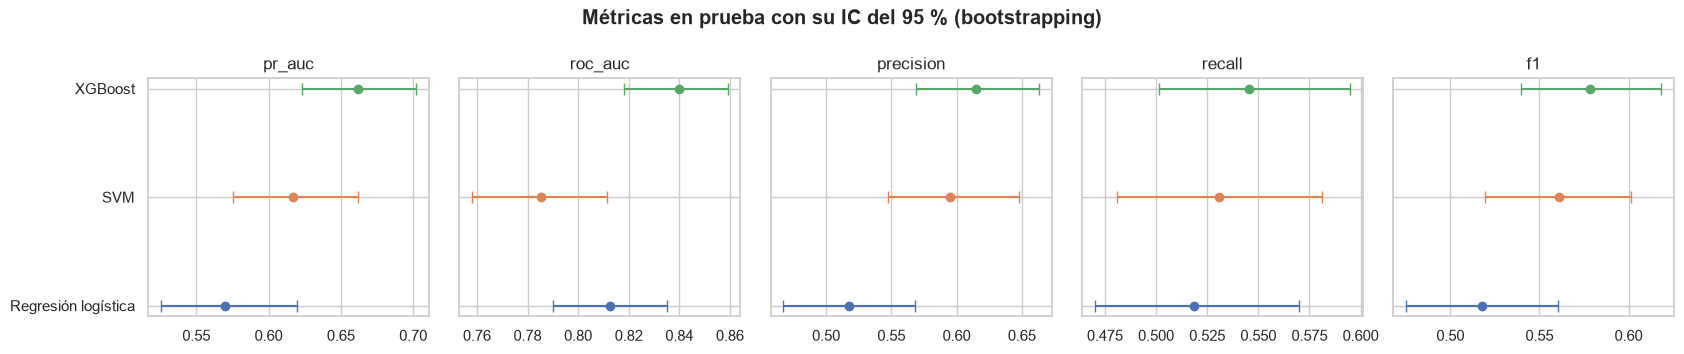

In [10]:
fig, axes = plt.subplots(1, len(METRICAS_BOOT), figsize=(17, 3.6), sharey=True)
colores = dict(zip(NOMBRES, sns.color_palette(n_colors=len(NOMBRES))))
for ax, m in zip(axes, METRICAS_BOOT):
    for i, n in enumerate(NOMBRES):
        est, inf, sup = ic.loc[(n, m)]
        ax.errorbar(est, i, xerr=[[est - inf], [sup - est]], fmt='o', color=colores[n], capsize=4)
    ax.set_title(m); ax.set_yticks(range(len(NOMBRES))); ax.set_yticklabels(NOMBRES)
fig.suptitle('Métricas en prueba con su IC del 95 % (bootstrapping)', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/05_intervalos_bootstrap.png', bbox_inches='tight'); plt.show()

**Qué vemos:** con \~400 abandonos en prueba, los intervalos son anchos. La PR-AUC de XGBoost va de 0,62 a 0,70 y su
recall, de 0,50 a 0,60. Cualquier cifra que se reporte al negocio debe ir con su rango. En PR-AUC, los intervalos de
XGBoost y de la regresión logística casi no se tocan; con la SVM sí se superponen. Por eso la sección 5 compara las
diferencias pareadas.

## 5. ¿El modelo elegido es mejor que los otros dos?

Que los intervalos se superpongan no prueba nada: con los mismos clientes, la comparación correcta es el **intervalo de
la diferencia** en cada réplica pareada. Para decir que el modelo elegido es mejor pedimos dos condiciones: que el
intervalo excluya el 0 y que la diferencia observada sea de al menos `UMBRAL_RELEVANTE` = 0,02, fijado antes de ver
los resultados. Se hacen 2 comparaciones × 5 métricas = 10 intervalos; con tantos, alguno podría excluir el 0 por azar,
así que las métricas sin umbral (PR-AUC y ROC-AUC) son las principales.

In [11]:
filas = []
for otro in [n for n in NOMBRES if n != ELEGIDO]:
    obs_a, obs_b = metricas(y_test, prob_test[ELEGIDO], UMBRALES[ELEGIDO]), metricas(y_test, prob_test[otro], UMBRALES[otro])
    for m in METRICAS_BOOT:
        d = boot[ELEGIDO][m] - boot[otro][m]
        inf, sup = np.percentile(d, [2.5, 97.5])
        p_boot = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
        dif = obs_a[m] - obs_b[m]
        filas.append({'comparación': f'{ELEGIDO} − {otro}', 'métrica': m, 'diferencia': dif, 'IC 2,5%': inf,
                      'IC 97,5%': sup, 'p_bootstrap': p_boot, 'IC excluye 0': (inf > 0) or (sup < 0),
                      'supera 0,02': abs(dif) >= UMBRAL_RELEVANTE})
comparacion = pd.DataFrame(filas).set_index(['comparación', 'métrica'])
comparacion['mejor de forma relevante'] = comparacion['IC excluye 0'] & comparacion['supera 0,02'] & (comparacion['diferencia'] > 0)
display(comparacion)

diferencia  IC 2,5%  IC 97,5%  p_bootstrap  IC excluye 0  supera 0,02  mejor de forma relevante
comparación                   métrica                                                                                                   
XGBoost − Regresión logística pr_auc          0.092    0.065     0.119        0.000          True         True                      True
                              roc_auc         0.027    0.014     0.041        0.000          True         True                      True
                              precision       0.098    0.057     0.139        0.000          True         True                      True
                              recall          0.027   -0.014     0.070        0.226         False         True                     False
                              f1              0.060    0.025     0.096        0.002          True         True                      True
XGBoost − SVM                 pr_auc          0.045    0.028     0.061        0.000          True         True                      True
                              roc_auc         0.055    0.040     0.070        0.000          True         True                      True
                              precision       0.020   -0.012     0.054        0.268         False        False                     False
                              recall          0.015   -0.020     0.047        0.410         False        False                     False
                              f1              0.017   -0.011     0.046        0.250         False        False                     False

**Prueba de McNemar.** Compara, cliente por cliente, en cuántos casos acierta solo un modelo. Se aplica a todos los
clientes de prueba (compara la exactitud) y solo a los que abandonan (compara el recall). Con menos de 25 casos en
desacuerdo se usa la versión exacta.

In [12]:
filas = []
acierta = {n: (prob_test[n] >= UMBRALES[n]).astype(int) == yt for n in NOMBRES}
for otro in [n for n in NOMBRES if n != ELEGIDO]:
    for grupo, mascara in [('todos (exactitud)', np.ones_like(yt, dtype=bool)), ('solo abandonos (recall)', yt == 1)]:
        a, b = acierta[ELEGIDO][mascara], acierta[otro][mascara]
        tabla = pd.crosstab(pd.Categorical(a, [True, False]), pd.Categorical(b, [True, False]), dropna=False).to_numpy()
        n10, n01 = tabla[0, 1], tabla[1, 0]
        res = mcnemar(tabla, exact=(n10 + n01) < 25, correction=True)
        filas.append({'comparación': f'{ELEGIDO} vs {otro}', 'clientes': grupo, f'solo acierta {ELEGIDO}': n10,
                      'solo acierta el otro': n01, 'p_valor': res.pvalue})
display(pd.DataFrame(filas).set_index(['comparación', 'clientes']))

solo acierta XGBoost  solo acierta el otro  p_valor
comparación                    clientes                                                                    
XGBoost vs Regresión logística todos (exactitud)                         156                    87    0.000
                               solo abandonos (recall)                    43                    32    0.248
XGBoost vs SVM                 todos (exactitud)                          78                    64    0.275
                               solo abandonos (recall)                    29                    23    0.488

**Qué vemos:**

- Frente a la regresión logística, XGBoost es mejor de forma relevante en PR-AUC (+0,092, IC 0,065 a 0,119), ROC-AUC,
  precisión y F1. En recall, la diferencia (+0,027) no se distingue de cero.
- Frente a la SVM, XGBoost ordena mejor a los clientes por riesgo (PR-AUC +0,045, IC 0,028 a 0,061; ROC-AUC +0,055).
  Pero con el umbral de cada uno, la precisión, el recall y el F1 no muestran diferencias claras.
- McNemar llega a lo mismo. XGBoost acierta en más clientes que la logística (156 frente a 87, p < 0,001), pero no se
  distingue de la SVM (78 frente a 64, p = 0,28). Entre los que abandonan, ninguno de los dos contrastes es
  significativo. No rechazar no significa que los modelos sean iguales: solo que con esta prueba no se ve la diferencia.

**Decisión:** XGBoost se mantiene. Ordena mejor el riesgo, que es lo que importa para decidir a quién contactar primero,
y entrega probabilidades directamente; la SVM necesitó una calibración aparte en el `04`. Su ventaja sobre la SVM en el
punto de operación es pequeña.

## 6. Calibración de las probabilidades

El cálculo de valor (`07`) multiplica probabilidades por pesos, así que importa que una probabilidad de 0,3 signifique
de verdad \~30 % de abandonos. Se agrupan los clientes de prueba en 10 grupos de igual tamaño por probabilidad predicha
y se compara la probabilidad media con la tasa real de cada grupo.

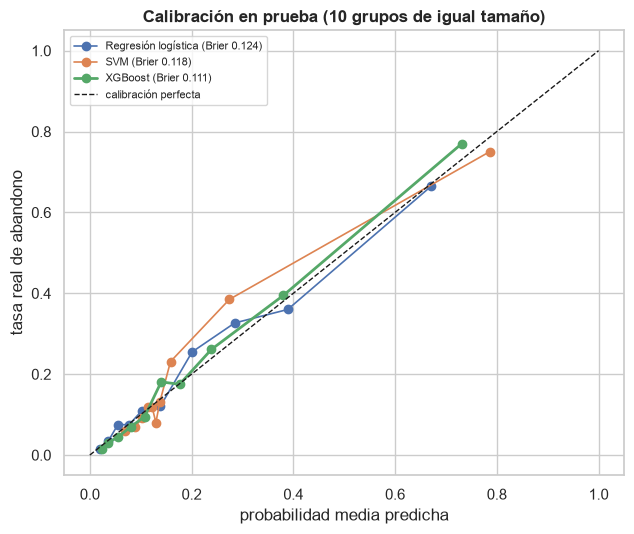

Probabilidad media predicha vs tasa real en prueba:
{'Regresión logística': '0.198', 'SVM': '0.198', 'XGBoost': '0.197'} | real: 0.204


In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for n in NOMBRES:
    real, pred = calibration_curve(y_test, prob_test[n], n_bins=10, strategy='quantile')
    ax.plot(pred, real, marker='o', lw=2 if n == ELEGIDO else 1.2,
            label=f'{n} (Brier {brier_score_loss(y_test, prob_test[n]):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='calibración perfecta')
ax.set_xlabel('probabilidad media predicha'); ax.set_ylabel('tasa real de abandono'); ax.legend(fontsize=8)
ax.set_title('Calibración en prueba (10 grupos de igual tamaño)', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/05_calibracion.png', bbox_inches='tight'); plt.show()

print('Probabilidad media predicha vs tasa real en prueba:')
print({n: f'{prob_test[n].mean():.3f}' for n in NOMBRES}, f'| real: {TASA_PRUEBA:.3f}')

**Qué vemos:** las tres curvas siguen de cerca la diagonal. La probabilidad media predicha (\~0,20) coincide con la tasa
real (0,204), y XGBoost tiene el menor Brier (0,111). Sus probabilidades se pueden usar directamente en el cálculo de
valor, sin recalibrar. Esto respalda la decisión del `04` de no usar pesos de clase ni SMOTE: allí inflaban la
probabilidad media al 26–41 %, cuando la tasa real es del 20 %.

## 7. Concentración del riesgo: ¿cuántos abandonos hay entre los más riesgosos?

Una campaña con presupuesto limitado contacta primero a los clientes con más riesgo. Si se ordena a los clientes de
prueba por probabilidad y se contacta al k % superior: qué parte de los contactados abandona (precisión), qué parte de
todos los abandonos se alcanza (recall) y cuántas veces supera eso a contactar al azar (*lift*).

In [14]:
orden = np.argsort(-prob_test[ELEGIDO])
filas = []
for k in [5, 10, 20, 30, 40, 50]:
    top = orden[:int(round(len(yt) * k / 100))]
    precision_k = yt[top].mean()
    filas.append({'contactar al k% más riesgoso': f'{k}%', 'clientes': len(top), 'abandonos alcanzados': int(yt[top].sum()),
                  'precisión': precision_k, 'recall': yt[top].sum() / yt.sum(), 'lift': precision_k / TASA_PRUEBA})
ganancia = pd.DataFrame(filas).set_index('contactar al k% más riesgoso')
display(ganancia)

,clientes,abandonos alcanzados,precisión,recall,lift
contactar al k% más riesgoso,,,,,
5%,100,94,0.940,0.231,4.612
10%,200,154,0.770,0.378,3.778
20%,399,232,0.581,0.570,2.853
30%,599,285,0.476,0.700,2.335
40%,799,320,0.401,0.786,1.965
50%,998,356,0.357,0.875,1.750


**Qué vemos:** el riesgo está muy concentrado. Entre el 5 % de clientes con más riesgo, 94 de cada 100 abandonan
(lift 4,6). Contactando al 20 % más riesgoso se alcanza el 57 % de los abandonos, con un 58 % de precisión. Pasar del
20 % al 40 % de contactados suma 22 puntos de recall, pero baja la precisión al 40 %. Esta tabla sirve para dimensionar
la campaña en el `07`: con un presupuesto limitado, el modelo permite gastar primero donde más rinde.

## 8. Desempeño por segmento

¿Dónde acierta y dónde falla el modelo elegido? Recall y precisión con su umbral, por grupo. `country` y `gender` no
entran al modelo (decisión ética del `04`); aquí se usan solo para auditar si el modelo trata distinto a cada grupo.
Los grupos de prueba son pequeños: las diferencias de pocos puntos no son concluyentes.

In [15]:
pred_el = (prob_test[ELEGIDO] >= UMBRALES[ELEGIDO]).astype(int)
seg = df.loc[es_prueba, ['products_number', 'active_member', 'age', 'country', 'gender']].copy()
seg['tramo_edad'] = pd.cut(seg['age'], [0, 30, 40, 50, 60, 120], right=False,
                           labels=['<30', '30–39', '40–49', '50–59', '60+'])
seg['real'], seg['pred'], seg['prob'] = yt, pred_el, prob_test[ELEGIDO]

def resumen_grupo(g):
    vp = ((g.real == 1) & (g.pred == 1)).sum()
    return pd.Series({'clientes': len(g), 'tasa_real_%': g.real.mean() * 100, 'prob_media_%': g.prob.mean() * 100,
                      'marcados_%': g.pred.mean() * 100,
                      'recall': vp / g.real.sum() if g.real.sum() else np.nan,
                      'precision': vp / g.pred.sum() if g.pred.sum() else np.nan})

tablas_seg = {}
for col in ['products_number', 'active_member', 'tramo_edad', 'country', 'gender']:
    tablas_seg[col] = seg.groupby(col, observed=True).apply(resumen_grupo, include_groups=False)
    print(f'--- {col} ---'); display(tablas_seg[col])

--- products_number ---


,clientes,tasa_real_%,prob_media_%,marcados_%,recall,precision
products_number,,,,,,
1,"1,005.000",27.164,26.301,26.269,0.553,0.572
2,925.000,8.432,8.176,3.243,0.192,0.500
3,55.000,80.000,78.040,100.000,1.000,0.800
4,12.000,100.000,90.635,100.000,1.000,1.000


--- active_member ---


,clientes,tasa_real_%,prob_media_%,marcados_%,recall,precision
active_member,,,,,,
0,946.000,27.273,24.315,23.256,0.566,0.664
1,"1,051.000",14.177,15.579,13.416,0.510,0.539


--- tramo_edad ---


,clientes,tasa_real_%,prob_media_%,marcados_%,recall,precision
tramo_edad,,,,,,
<30,322.000,7.453,8.204,1.242,0.083,0.500
30–39,863.000,12.051,11.433,2.317,0.135,0.700
40–49,481.000,30.769,30.429,37.630,0.642,0.525
50–59,168.000,59.524,49.873,75.000,0.910,0.722
60+,95.000,25.263,28.168,26.316,0.667,0.640


--- country ---


,clientes,tasa_real_%,prob_media_%,marcados_%,recall,precision
country,,,,,,
France,999.000,15.115,17.454,14.815,0.570,0.581
Germany,513.000,35.088,24.286,24.172,0.544,0.790
Spain,485.000,15.670,19.547,18.351,0.500,0.427


--- gender ---


,clientes,tasa_real_%,prob_media_%,marcados_%,recall,precision
gender,,,,,,
Female,899.000,25.473,21.112,20.133,0.546,0.691
Male,"1,098.000",16.211,18.575,16.393,0.545,0.539


**Qué vemos:**

- Casi todos los clientes con 3 o 4 productos abandonan, y el modelo los marca a todos. Con 2 productos (tasa del 8 %),
  el modelo casi no marca a nadie (3 %) y alcanza solo el 19 % de sus abandonos: son los que más se le escapan.
- Por edad, el riesgo y los aciertos se concentran entre los 40 y los 59 años (recall de 0,64 y 0,91). En menores de 40,
  el modelo marca al 1–2 % y alcanza el 8–14 % de los abandonos: son abandonos que no encajan con su perfil.
- Entre activos e inactivos el recall es parecido (0,57 frente a 0,51); la precisión es más alta en los inactivos.

**Auditoría** (con variables que no entran al modelo): el recall es casi igual entre mujeres y hombres (0,546 frente a
0,545) y entre países (0,50 a 0,57), así que el modelo alcanza una proporción parecida de los que abandonan en cada
grupo. Pero subestima el riesgo en Alemania (probabilidad media del 24 % frente al 35 % real) y en mujeres (21 % frente
a 25 %), y lo sobreestima en España y en hombres. Por eso su precisión varía: 0,79 en Alemania frente a 0,43 en España.
Antes de usarlo en un banco hay que revisar esta calibración por grupo.

## 9. Oportunidades de mejora (evidencia en validación cruzada)

Dos cambios posibles, evaluados **solo con validación cruzada en entrenamiento** (las mismas 5 particiones) para no
gastar la prueba. Se usa XGBoost con los hiperparámetros elegidos en el `04`; la única diferencia entre variantes son
las variables.

1. **Incluir `country`.** En el `03` Alemania abandona el doble que Francia y España. Se excluyó por ética y porque no
   existe en un banco colombiano; aquí se mide cuánto desempeño cuesta esa decisión.
2. **Variables derivadas** (sugeridas en la Práctica 4 del curso): saldo en cero, razón saldo/salario, tener un solo
   producto o tres o más, e interacción edad × miembro activo.

In [16]:
NUMERICAS = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']
hiper = seleccion['hiperparametros'][ELEGIDO]

def derivar(d):
    d = d.copy()
    d['saldo_cero'] = (d['balance'] == 0).astype(float)
    d['saldo_salario'] = d['balance'] / (d['estimated_salary'] + 1)
    d['un_producto'] = (d['products_number'] == 1).astype(float)
    d['tres_o_mas_productos'] = (d['products_number'] >= 3).astype(float)
    d['edad_x_activo'] = d['age'] * d['active_member']
    return d

def pipeline_xgb(numericas, categoricas, binarias):
    prep = ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),
        ('binarias', 'passthrough', binarias),
    ])
    modelo = XGBClassifier(**hiper, eval_metric='logloss', random_state=SEMILLA, n_jobs=1)
    return Pipeline([('preparar', prep), ('modelo', modelo)])

base_train = df.loc[~es_prueba].copy()
base_train[NUMERICAS] = base_train[NUMERICAS].astype(float)
derivadas = ['saldo_cero', 'saldo_salario', 'un_producto', 'tres_o_mas_productos', 'edad_x_activo']
VARIANTES = {
    'actual (8 variables)': (NUMERICAS, ['products_number'], ['credit_card', 'active_member']),
    '+ country': (NUMERICAS, ['products_number', 'country'], ['credit_card', 'active_member']),
    '+ variables derivadas': (NUMERICAS + ['saldo_salario', 'edad_x_activo'], ['products_number'],
                              ['credit_card', 'active_member', 'saldo_cero', 'un_producto', 'tres_o_mas_productos']),
}
datos = derivar(base_train)
res_var = {}
for nombre, (num, cat, binr) in VARIANTES.items():
    r = cross_validate(pipeline_xgb(num, cat, binr), datos[num + cat + binr], y_train, cv=cv,
                       scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}, n_jobs=-1)
    res_var[nombre] = r

filas = []
for nombre, r in res_var.items():
    d = r['test_pr_auc'] - res_var['actual (8 variables)']['test_pr_auc']
    filas.append({'variante': nombre, 'pr_auc_media': r['test_pr_auc'].mean(), 'pr_auc_desv': r['test_pr_auc'].std(),
                  'roc_auc_media': r['test_roc_auc'].mean(), 'dif_pr_auc_vs_actual': d.mean(),
                  'dif_min_por_particion': d.min(), 'dif_max_por_particion': d.max()})
mejoras = pd.DataFrame(filas).set_index('variante')
display(mejoras)

,pr_auc_media,pr_auc_desv,roc_auc_media,dif_pr_auc_vs_actual,dif_min_por_particion,dif_max_por_particion
variante,,,,,,
actual (8 variables),0.679,0.017,0.848,0.000,0.000,0.000
+ country,0.693,0.019,0.858,0.015,0.009,0.021
+ variables derivadas,0.678,0.017,0.847,-0.000,-0.006,0.003


**Qué vemos:**

- Incluir `country` sube la PR-AUC en 0,015 en promedio. Mejora en las 5 particiones (entre 0,009 y 0,021), pero queda
  por debajo del umbral relevante de 0,02. Excluirlo cuesta poco desempeño, aunque explica parte de la subestimación en
  Alemania de la sección 8. Como `country` no existe en un banco colombiano, su equivalente sería una variable regional
  o de segmento del propio banco, que habría que evaluar con sus datos.
- Las variables derivadas no aportan (diferencia de \~0). Los árboles ya encuentran por sí solos esos cortes: saldo en
  cero, número de productos y edad × actividad.

*Nota:* la variante "actual" (0,679) difiere un poco del PR-AUC del `04`. Aquí el preprocesamiento se reescribió sin
escalado (los árboles no lo necesitan), y eso cambia el orden de las columnas que muestrea `colsample_bytree`. Las tres
variantes de esta tabla sí son comparables entre sí.

## 10. Conclusiones

XGBoost queda como modelo final. Es el que mejor ordena a los clientes por riesgo en prueba (PR-AUC 0,662, IC 0,62–0,70,
3,2 veces la línea base) y supera de forma relevante a la regresión logística. Frente a la SVM ordena mejor, aunque en
el punto de operación la diferencia no es concluyente.

Con el umbral de máximo F1 contacta al 18 % de la cartera: 6 de cada 10 contactados sí iban a abandonar, frente a 2 de
cada 10 al azar, y se alcanza a más de la mitad de los que abandonan. El 10 % más riesgoso concentra el 38 % de los
abandonos. Sus probabilidades están calibradas, así que el `07` las usa directamente para calcular la ganancia.

Su ventaja viene de captar relaciones no lineales (la edad y el número de productos no actúan en línea recta, y la
actividad cambia el efecto de la edad) con una configuración conservadora, que deja poca brecha entre entrenamiento y
prueba.

Para mejorarlo harían falta datos de comportamiento (transacciones, reclamos, uso de canales), porque los abandonos de
clientes con 2 productos o menores de 40 años casi no se detectan. También hay que revisar la calibración en Alemania y
en mujeres, reentrenar y validar con datos del propio banco, y fijar el umbral por ganancia y no por F1 (`07`).